In [139]:
import sys
sys.path.append('C:\\Program Files\\IBM\\ILOG\\CPLEX_Studio210\\cplex\\python\\20.1\\x64_win64')
sys.path.append("C:\\ProgramData\\anaconda3\\Lib\\site-packages")
import numpy as np
import pandas as pd
from docplex.mp.model import Model
import matplotlib.pyplot as plt
import random

# define the parameters
PARAMS = {
    'P': 10,        # number of caissons
    'T': 100,      # horizon
    'Cmax':5,      # maximum number of tasks of one cluster
    'window_size': 10,   # window size 10
    'advanced': 3,          # advanced time
    'K': 5.993,         # leakage coefficient
    'minGap' : 0,
    'maxGap' : 25
}  

# initialize the random values
random.seed(42)
# alpha_values = [round(random.uniform(0.03, 0.08), 3) for _ in range(PARAMS['P'])]
alpha_values = [round(random.uniform(0.01, 0.05), 3) for _ in range(PARAMS['P'])]   # degradation rate for each caisson
initial_p_values = [round(random.uniform(3.2, 3.5), 2) for i in range(PARAMS['P'])]
print("alpha values:", alpha_values)

# function to group the tasks within a window
def clustering_CR(update_df, df_window, df_window_prev, window_size, window_start, global_task_count, window_start_prev):
    """Grouping model"""
    # add preprocessing here
    update_df_new = update_df.copy()
    if df_window.empty or window_size < 1 or df_window.shape[0] ==1:
        print(f"warning: window {window_start} has no tasks or window size is invalid")
        return df_window, window_start, update_df_new  # return the original dataframe if no tasks in the window

    N = df_window.shape[0]  # number of tasks in the window
    print (N)
    # if df_window_prev is None:
    #     df_window_prev = df_window.copy()
    # else:
    #     df_window_prev = None
    
    mdl = Model('Dynamic_Window_Clustering')
    
    # define the variables
    data_pos_num = window_size + 1
    theta = mdl.binary_var_matrix(N, data_pos_num, name='theta')
    cluster = mdl.binary_var_list(data_pos_num, name='cluster')

    a = [0] * N
    b = [0] * N

    M1 = 1
    M = 11
    # objective function
    mdl.minimize(mdl.sum(cluster[t] for t in range(data_pos_num)))

        
    # 2. at least one tasks needed to activate the cluster
    mdl.add_constraints(theta[n, t] <= cluster[t] for n in range(N) for t in range(data_pos_num))

    # 1. every task must be assigned to one cluster
    mdl.add_constraints(mdl.sum(theta[n, t] for t in range(data_pos_num)) == 1 for n in range(N))
    
    # 3. maximum capacity in each cluster
    mdl.add_constraints(mdl.sum(theta[n, t] for n in range(N)) <= PARAMS['Cmax'] for t in range(data_pos_num))

    # 6. define the possible advanced or delayed range for each task
    for n in range(N):
        local_time = df_window.iloc[n]['window_time']
        a[n] = max(0, local_time - PARAMS['advanced'])
        b[n] = min(data_pos_num, local_time + int((3.2 - 3.0)/alpha_values[int(df_window.iloc[n]["CSEM"])]) - 2)


    # for n in range(N):
    #     for t in range(data_pos_num):
    #         mdl.add_constraints(t * center[k,t] >= a[n] - M * (1 - theta[n, k]) - M * (1 - center[k, t]) for k in range(data_pos_num))
    #         mdl.add_constraints(t * center[k,t] <= b[n] + M1 * (1 - theta[n, k]) for k in range(data_pos_num))
    

    for n in range(N):
        for t in range(data_pos_num):
            mdl.add_constraint(t * theta[n,t] + a[n] * (1 - theta[n, t]) >= a[n])
            mdl.add_constraint(t * theta[n,t] + b[n] * (1 - theta[n, t]) <= b[n])

    
    for c in df_window['CSEM'].unique():
        df_prev_csem = update_df_new[update_df_new['CSEM'] == c] if update_df_new is not None else pd.DataFrame()
        indices = df_prev_csem.index.tolist()
        if len(indices) > 1:
            for i in range(len(indices)-1):
                n1 = df_prev_csem.index.get_loc(indices[i])
                if n1 in df_window_prev.index:
                    for t in range(data_pos_num):
                        n2 = df_prev_csem.index.get_loc(indices[i+1])
                        # mdl.add_constraint(window_start + t*theta[n2, t] - update_df_new.iloc[n1]['CENTER']  >= PARAMS['minGap'])
                        # print (c)
                        mdl.add_constraint((int(window_start) + t * theta[n2, t] - int(update_df_new.iloc[n1]['CENTER']))  <=  PARAMS['maxGap'])
                    break
            

    # solve the model
    solution = mdl.solve()

    if not solution:
        print(f"Failed to solve the problem: {mdl.solve_details.status}")
        return None
    
    # result processing
    # convert local time back to original time and get the center for each task
    centers = {}
    for n in range(N):
            for t in range(data_pos_num):
                if solution.get_value(theta[n, t]) == 1.0:  # find the center for each cluster
                    # print(f"Task {n} (CSEM={df_window.iloc[n]['CSEM']}) assigned to cluster {t + window_start}")
                    centers[n] = t + window_start  # change the time back to the original time
                    break

    index_n_list = df_window.INDEX.tolist()

    for n in range(len(index_n_list)):
        for t in range(data_pos_num):
            if solution.get_value(theta[n, t]) == 1.0:
                df_window.loc[df_window['INDEX'] == index_n_list[n], 'CENTER'] = centers.get(n, 0)

    for n in range(N):
        for t in range(data_pos_num):
            if solution.get_value(theta[n, t]) == 1.0:
                update_df_new.loc[update_df_new['INDEX'] == index_n_list[n], 'CENTER'] =  centers.get(n, 0)

    return df_window, window_start, update_df_new

# function to calculate the gas leakage before clustering
def calculate_gas_leakage_before(df, T):
    total_leakage = 0

    for csem in df['CSEM'].unique():
        # filter the data for the current CSEM
        csem_data = df[df['CSEM'] == csem]
        x_operations = csem_data[csem_data['OPERATION'] == 'x']
        y_operations = csem_data[csem_data['OPERATION'] == 'y']

        # if there are more than two CR, add 1.80 for each additional CR (apart from these two) and calculate the leakage for the first and last CR independently
        if len(x_operations) >= 2:
            total_leakage += 1.80 * (len(x_operations) - 1)

        # deal with the first 'x' operation
        first_x = x_operations.iloc[0]
        if not pd.isna(first_x['INITIALP']):
            total_leakage += (first_x['INITIALP'] - 3.2) * PARAMS['K']

        # deal with the last 'x' operation
        last_x = x_operations.iloc[-1]
        if not y_operations.empty:
            # if there is a 'y' operation
            total_leakage += 1.80
        else:
            # if there is no 'y' operation
            alpha = alpha_values[last_x['CSEM']]
            total_leakage += (T - last_x['DATE'] - 1) * alpha * PARAMS['K']

    return total_leakage

# function to calculate the gas leakage after clustering
def calculate_gas_leakage_after(df, T):
    total_leakage = 0

    for csem in df['CSEM'].unique():
        # filter the data for the current CSEM
        csem_data = df[df['CSEM'] == csem]
        x_operations = csem_data[csem_data['OPERATION'] == 'x']
        y_operations = csem_data[csem_data['OPERATION'] == 'y']
        alpha = alpha_values[csem]

        # deal with the 'x' operations in the middle
        for i in range(1, len(x_operations)):
            current_x = x_operations.iloc[i]
            previous_x = x_operations.iloc[i - 1]
            center_diff = current_x['CENTER'] - previous_x['CENTER'] - 1
            total_leakage += center_diff * alpha * PARAMS['K']

        # deal with the first 'x' operation
        if not x_operations.empty:
            first_x = x_operations.iloc[0]
            total_leakage += first_x['CENTER'] * alpha * PARAMS['K']

        # deal with the last 'x' operation
        last_x = x_operations.iloc[-1]
        if not y_operations.empty:
            # if there is a 'y' operation
            y_center = y_operations['CENTER'].iloc[0]
            total_leakage += (y_center - last_x['CENTER']) * alpha * PARAMS['K']
        else:
            # if there is no 'y' operation
            total_leakage += (T - last_x['DATE'] - 1) * alpha * PARAMS['K']

    return total_leakage

def main(window_size):
    """Main function"""
    
    df = pd.read_csv('maintenance_plan.csv')
    df_init = df.copy()
    df_history_list = []
    df_history_list.append(df_init)
    sliding_windows_starts = []
    sliding_windows_ends = []
    # df['CENTER'] = 0  # initialize the center column
    df['CENTER'] = df['DATE']  # initialize the center column
    # global variables
    global_task_count = [0] * PARAMS['T'] * 2
    window_start = 0
    df_window_prev = None
    window_start_prev = 0
    updated_df = None
    while window_start <= PARAMS['T']:
        # dynamic window selection
        window_end = window_start + window_size
        if window_end > PARAMS['T']:
            window_end = PARAMS['T']
        
        sliding_windows_starts.append(window_start)
        sliding_windows_ends.append(window_end)
        mask = (df['DATE'] >= window_start) & (df['DATE'] <= window_end) & (df['OPERATION']== 'x')  

        window_df = df.loc[mask].copy()
        
        # task local time conversion
        window_df['window_time'] = window_df['DATE'] - window_start

        first_tasks = window_df.groupby('CSEM', group_keys=False).apply(lambda x: x.sort_values('DATE').iloc[0])
        if df_window_prev is None:
            df_window_prev = first_tasks.copy()

        if updated_df is None:
            updated_df = df.copy()
        
        # clustering these first tasks in the window
        clustered_df , window_start_prev, updated_df = clustering_CR(updated_df, first_tasks, df_window_prev, window_size, window_start, global_task_count, window_start_prev)
        
        if clustered_df is not None:
            # update the center column of original dataframe
            center_map = clustered_df.set_index('INDEX')['CENTER']

            df.loc[df['INDEX'].isin(center_map.index), 'CENTER'] = df['INDEX'].map(center_map)

            # update the secondary tasks time
            update_secondary_tasks(df, clustered_df, window_start, window_end)
        
        # # slide the window to the last cluster center + 1 !!! previous methods
        # if len(first_tasks) != 0:
        #     max_window_start = clustered_df['CENTER'].max() + 1  # overlapping window
        # else:
        #     max_window_start = window_start + window_size
        # # slide the window
        # max_window_start = clustered_df['CENTER'].max() + 1  # overlapping window
        # min_window_start = max_window_start
        # for caisson in clustered_df["CSEM"].unique():
        #     # get the tasks in the same caisson
        #     tasks = df[
        #         (df['CSEM'] == caisson) & 
        #         (df['DATE'].between(window_start, window_end))
        #     ]
        
        #     if len(tasks) > 1:
        #         # get the second task index
        #         second_idx = tasks.index[1]
        #         date_now = df.loc[second_idx]['DATE']
        #         if min_window_start > date_now:
        #             min_window_start = date_now
        
        # window_start = min(max_window_start,min_window_start)


        # slide the window to the next task that haven't been clustered yet   !!! new version
        second_dates = []
        for caisson in clustered_df["CSEM"].unique():
            # get tasks in the current window of this caisson 
            tasks = df[
                (df['CSEM'] == caisson) & 
                (df['OPERATION'] == 'x') &
                (df['DATE'].between(window_start, window_end))
            ].sort_values('DATE')

            # if at least 2 tasks, then take the date of the second 
            if len(tasks) > 1:
                second_date = tasks.iloc[1]['DATE']
                second_dates.append(second_date)

        # if at least one valid "second_date", then update the start point of the window 
        if second_dates:
            window_start = min(second_dates)
        else:
            # fallback：keep the old logic or advance by the length of a window 
            window_start = window_start + window_size  # or clustered_df['CENTER'].max() + 1
        # ---------------

        df_history_list.append(df.copy())

        if window_end>=PARAMS['T']:
            break

        df.loc[df['INDEX'].isin(center_map.index), 'DATE'] = df['INDEX'].map(center_map)
        df_window_prev = clustered_df
    # Updates the center column of the RE operation, which will not be grouped
    df.loc[df['OPERATION'] == "y", 'CENTER'] = df.loc[df['OPERATION'] == "y", 'DATE']

    # Processing of the remaining tasks that are not assigned to a center and cannot be updated
    mask_remain = (df['OPERATION'] == "x") & (df['CENTER'] == 0)
    df.loc[mask_remain, 'CENTER'] = df.loc[mask_remain, 'DATE']
    
    # result verification
    # assert df['CENTER'].notna().all(), "Some tasks are not clustered"
    return df, df_history_list, sliding_windows_starts, sliding_windows_ends

# function to update the secondary tasks date of each window
def update_secondary_tasks(main_df, clustered_df, window_start, window_end):
    """Update the secondary tasks time"""
    for caisson in clustered_df["CSEM"].unique():
        # get the tasks in the same caisson
        tasks = main_df[
            (main_df['CSEM'] == caisson) & 
            (main_df['DATE'].between(window_start, window_end)) 
        ]
        tasks = main_df[
            (main_df['CSEM'] == caisson) & 
            (main_df['DATE'].between(window_start, window_end)) & 
            (main_df['OPERATION'] == 'x')
        ]
        
        if len(tasks) > 1:
            # get the second task index
            second_idx = tasks.index[1]
            
            # get the previous center time amd calculate the new time for the second task
            center_time = clustered_df.loc[clustered_df['CSEM'] == caisson, 'CENTER'].iloc[0]
            
            # calulate the new time
            alpha = alpha_values[caisson]
            new_date = int(center_time + 1 + (3.5-3.2)/alpha)
            
            # update the time
            main_df.loc[second_idx, ['DATE', 'CENTER']] = new_date, new_date





alpha values: [0.036, 0.011, 0.021, 0.019, 0.039, 0.037, 0.046, 0.013, 0.027, 0.011]


In [140]:
result_df, df_history_list, sliding_windows_starts, sliding_windows_ends = main(PARAMS['window_size']) # with sliding window


8


C:\Users\wu.wenbo\AppData\Local\Temp\ipykernel_21488\3062072795.py:233: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False).apply(lambda x: x.sort_values('DATE').iloc[0])


7


C:\Users\wu.wenbo\AppData\Local\Temp\ipykernel_21488\3062072795.py:233: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False).apply(lambda x: x.sort_values('DATE').iloc[0])


6


C:\Users\wu.wenbo\AppData\Local\Temp\ipykernel_21488\3062072795.py:233: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False).apply(lambda x: x.sort_values('DATE').iloc[0])


C:\Users\wu.wenbo\AppData\Local\Temp\ipykernel_21488\3062072795.py:233: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False).apply(lambda x: x.sort_values('DATE').iloc[0])
C:\Users\wu.wenbo\AppData\Local\Temp\ipykernel_21488\3062072795.py:233: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False).apply(lambd

In [141]:
print(df_history_list[-1].head())  # 显示前5行
print(df_history_list[-1].columns)  # 显示列名
print(df_history_list[-1].info())   # 显示列数据类型、非空数等信息



   INDEX  CSEM  INITIALP OPERATION  DATE  CENTER
0      0     0      3.27         x     0       0
1      1     0      3.27         x     8       8
2      2     0      3.27         x    20      20
3      3     0      3.27         y    28      28
4      4     1      3.35         x    13      13
Index(['INDEX', 'CSEM', 'INITIALP', 'OPERATION', 'DATE', 'CENTER'], dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25 entries, 0 to 24
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   INDEX      25 non-null     int64  
 1   CSEM       25 non-null     int64  
 2   INITIALP   25 non-null     float64
 3   OPERATION  25 non-null     object 
 4   DATE       25 non-null     int64  
 5   CENTER     25 non-null     int64  
dtypes: float64(1), int64(4), object(1)
memory usage: 1.3+ KB
None


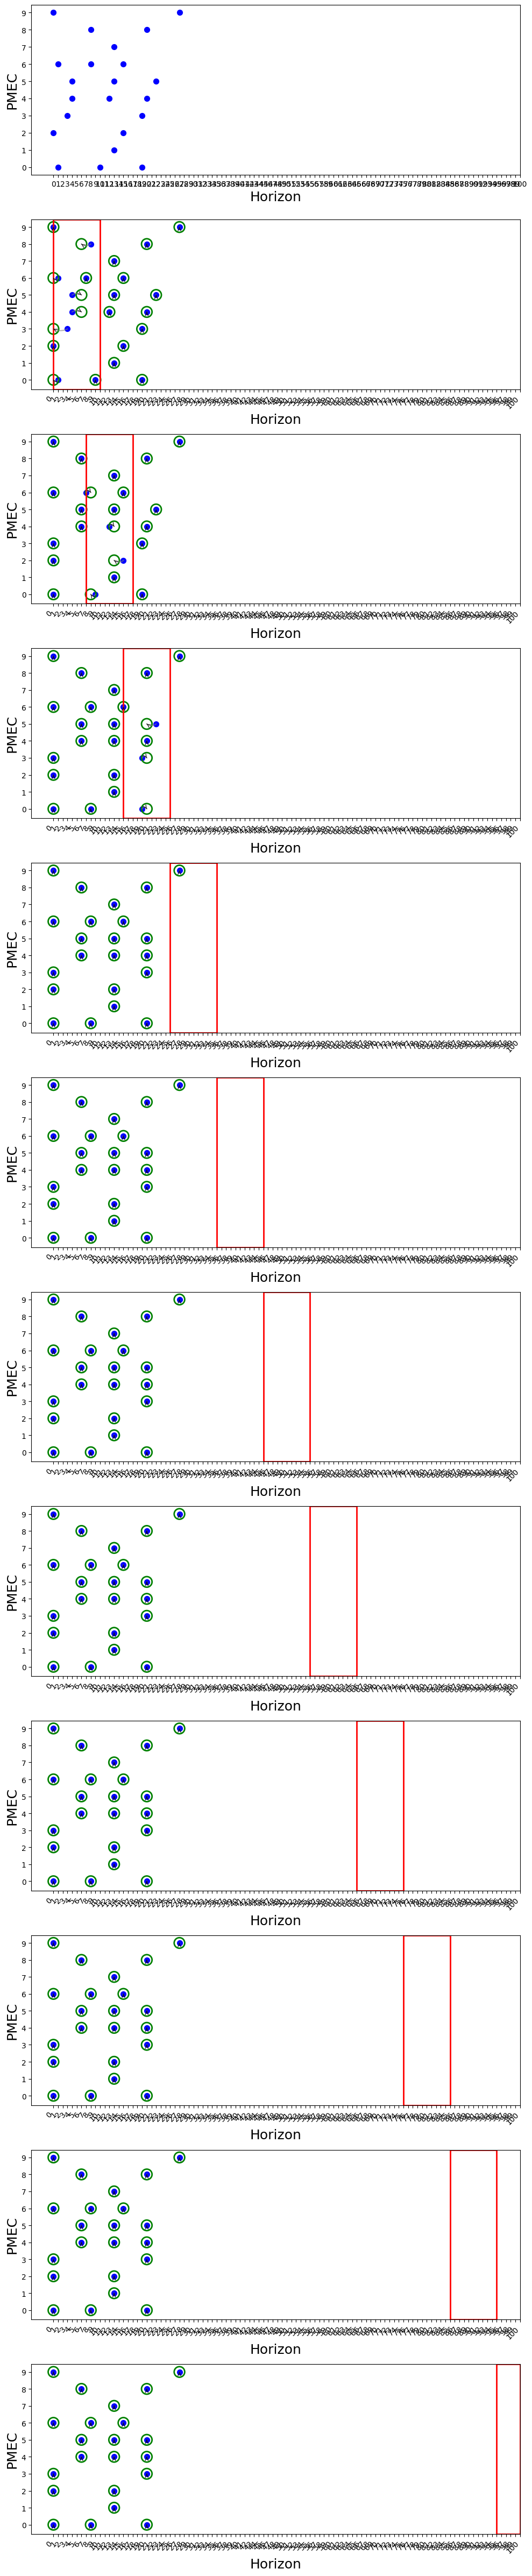

In [142]:
# print the results - sliding window
import matplotlib.pyplot as plt

def plot_all_dfs(df_history_list):
    n = len(df_history_list)  # calculate the number of tasks
    fig, axes = plt.subplots(nrows=n, ncols=1, figsize=(10, 4 * n), sharex=True)
    
    if n == 1:
        axes = [axes]  # make axes iterable if there's only one subplot
    for i, df in enumerate(df_history_list):
        ax = axes[i]
        df_x = df[df['OPERATION'] == 'x'] # if we just draw x   replace df with df_x
        if i==0:
            ax.scatter(df_x['DATE'], df_x['CSEM'], color='blue', marker='o', label='DATE', s=50)
            ax.set_ylabel('PMEC')
            # ax.set_title('Sliding window grouping results')
            # ax.legend()
            axes[i].set_xlabel('Horizon', fontsize=18)  
            axes[i].set_ylabel('PMEC', fontsize=18)  
            y_ticks = np.arange(0, PARAMS['P'], 1) # axe x ticks from 0 to T
            ax.set_yticks(y_ticks)
            ax.tick_params(labelbottom=True)
            continue
    
        
        # plot the data points
        # colors = ['orange' if op == 'y' else 'blue' for op in df['OPERATION']] # if we draw x and y 
        # ax.scatter(df['DATE'], df['CSEM'], color='blue', marker='o', label='DATE', s=20)
        # ax.scatter(df['CENTER'], df['CSEM'], edgecolors='green', facecolors='none', marker='o', label='CENTER', s=100, linewidths=2)
        

        df_x = df[df['OPERATION'] == 'x'] # if we just draw x   replace df with df_x
        ax.scatter(df_x['DATE'], df_x['CSEM'], color='blue', marker='o', label='DATE', s=50)
        ax.scatter(df_x['CENTER'], df_x['CSEM'], edgecolors='green', facecolors='none', marker='o', label='CENTER', s=200, linewidths=2)
        
        # add the flowing arrows
        for j in range(len(df_x)):
            # x_start, y_start = df['DATE'][j], df['CSEM'][j]  # if we draw x and y
            # x_end, y_end = df['CENTER'][j], df['CSEM'][j]
 
            x_start, y_start = df_x['DATE'].iloc[j], df_x['CSEM'].iloc[j] ## if we just draw x
            x_end, y_end = df_x['CENTER'].iloc[j], df_x['CSEM'].iloc[j]
            
            # calculate the mid point for the curve
            mid_x = (x_start + x_end) / 2
            mid_y = y_start + (0.2 if x_end > x_start else -0.2)  # rise or fall the curve
            
            # create a quadratic Bezier curve
            t = np.linspace(0, 1, 100)
            curve_x = (1 - t) ** 2 * x_start + 2 * (1 - t) * t * mid_x + t ** 2 * x_end
            curve_y = (1 - t) ** 2 * y_start + 2 * (1 - t) * t * mid_y + t ** 2 * y_end
            
            ax.plot(curve_x, curve_y, color='gray', alpha=0.6)
            ax.annotate('', xy=(curve_x[-1], curve_y[-1]), xytext=(curve_x[-2], curve_y[-2]),
                        arrowprops=dict(arrowstyle='->', color='black', alpha=0.8))
        # add windows
        start = sliding_windows_starts[i-1]
        end = sliding_windows_ends[i-1]

        ax.add_patch(plt.Rectangle((start, ax.get_ylim()[0]), end-start, ax.get_ylim()[1]-ax.get_ylim()[0],
                                      edgecolor='red', facecolor='none', linewidth=2))
        
        x_min, x_max = int(df_x['DATE'].min()), int(df_x['DATE'].max())  
        # x_ticks = np.arange(x_min, x_max + 1, 1)  
        x_ticks = np.arange(0, PARAMS['T'] + 1, 1) # axe x ticks from 0 to T
        ax.set_xticks(x_ticks)
        y_ticks = np.arange(0, PARAMS['P'], 1) # axe x ticks from 0 to T
        ax.set_yticks(y_ticks)
        ax.set_xticklabels(x_ticks, rotation=45, ha="right")  
        axes[i].set_xlabel('Horizon', fontsize=18)  
        axes[i].set_ylabel('PMEC', fontsize=18)  
        ax.tick_params(labelbottom=True) 
        
    # axes[-1].set_xlabel('Time Units')  
    plt.tight_layout()
    plt.show()

# plot the results

plot_all_dfs(df_history_list)


In [ ]:

df_history_list[3]

,INDEX,CSEM,INITIALP,OPERATION,DATE,CENTER
0,0,0,3.27,x,1,1
1,1,0,3.27,x,12,12
2,2,0,3.27,x,19,21
3,3,0,3.27,y,28,28
4,4,1,3.35,x,12,12
5,5,2,3.21,x,1,1
6,6,2,3.21,x,12,12
7,7,3,3.26,x,1,1
8,8,3,3.26,x,19,21
9,9,4,3.39,x,1,1


Cost before grouping: 220
Cost after grouping: 80
Gas leakage before clustering: 42.114
Gas leakage after clustering: 41.803


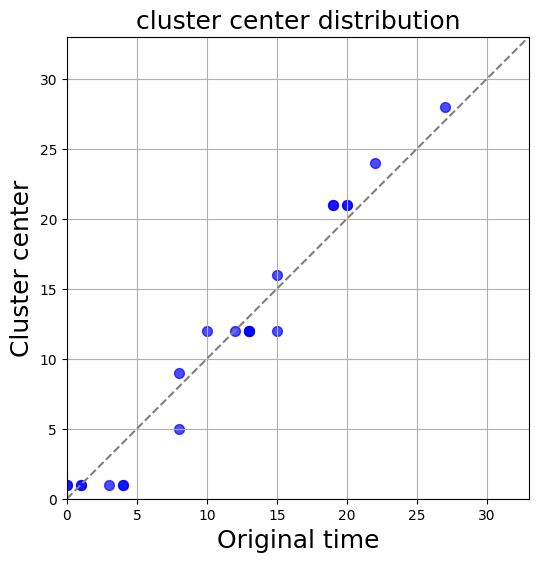

Center counts: CENTER
1     7
12    6
21    4
24    1
9     1
16    1
5     1
28    1
Name: count, dtype: int64
Results:
    INDEX  CSEM  INITIALP OPERATION  DATE  CENTER
0       0     0      3.27         x     1       1
1       1     0      3.27         x    12      12
2       2     0      3.27         x    21      21
4       4     1      3.35         x    12      12
5       5     2      3.21         x     1       1
6       6     2      3.21         x    12      12
7       7     3      3.26         x     1       1
8       8     3      3.26         x    21      21
9       9     4      3.39         x     1       1
10     10     4      3.39         x    12      12
11     11     4      3.39         x    21      21
13     13     5      3.36         x     1       1
14     14     5      3.36         x    12      12
15     15     5      3.36         x    24      24
16     16     6      3.27         x     1       1
17     17     6      3.27         x     9       9
18     18     6      3.27    

In [ ]:

# calculate the cost before grouping
operation_x_count = (result_df['OPERATION'] == 'x').sum()
# operation_y_count = (result_df['OPERATION'] == 'y').sum()
# before_cost = operation_x_count * 10 + operation_y_count * 100
before_cost = operation_x_count * 10 

print(f"Cost before grouping: {before_cost}")
# calculate the cost after grouping
operation_x_center_unique_count = result_df[result_df['OPERATION'] == 'x']['CENTER'].nunique()
# operation_y_count = (result_df['OPERATION'] == 'y').sum()
# after_cost = operation_x_center_unique_count * 10 + operation_y_count * 100
after_cost = operation_x_center_unique_count * 10 

print(f"Cost after grouping: {after_cost}")

# calculate the gas leakage before clustering
df = pd.read_csv('maintenance_plan.csv')
leakage_before = round(calculate_gas_leakage_before(df, PARAMS['T']), 3)

print(f"Gas leakage before clustering: {leakage_before}")

# calculate the gas leakage after clustering
leakage_after = round(calculate_gas_leakage_before(result_df, PARAMS['T']), 3)
print(f"Gas leakage after clustering: {leakage_after}")


# Plot1: cluster center vs original time
plt.figure(figsize=(6, 6))
# set colors：if OPERATION == "y"，red else blue   # if we draw x and y previous version
# colors = ['orange' if op == 'y' else 'blue' for op in result_df['OPERATION']]

df = df[df['OPERATION'] == 'x']  # if we just draw x
result_df = result_df[result_df['OPERATION'] == 'x']  # if we just draw x
plt.scatter(df['DATE'], result_df['CENTER'], color = 'blue', alpha=0.7, s=50)

# title and labels
plt.title("cluster center distribution", fontsize=18)
plt.xlabel("Original time", fontsize=18)
plt.ylabel("Cluster center", fontsize=18)
plt.grid(True)

# set x and y axis limits
max_range = max(result_df['DATE'].max(), result_df['CENTER'].max()+5)
plt.xlim(0, max_range)
plt.ylim(0, max_range)

# add diagonal line
plt.plot([0, max_range], [0, max_range], color='gray', linestyle='--', label='45° diagonal')
# set aspect ratio to be equal
plt.gca().set_aspect('equal')
plt.show()

center_counts = result_df['CENTER'].value_counts()
print("Center counts:", center_counts)
print("Results:")
print(result_df)
result_df.to_csv('result.csv', index=False)
print("Result saved to result.csv")